# Course 12: AI for Accessibility
## Session 4: Sign languages and hand pose

**Goal:** represent a hand as 21 landmarks, normalize them for position, size, rotation and handedness, and classify synthetic handshapes on signers the model has never seen.

**How to use this notebook:** run the cells from top to bottom. Cells marked `TODO` are for you to complete. The lab guide, quiz and assignment for this session are in the course document.

**Testing note:** every cell without a NOT RUN label was run once on a CPU (November 2026) on small built-in or synthetic data. Cells labelled NOT RUN need a library, a dataset download or a GPU; run them on Kaggle or Colab.

### 1. By hand first: normalizing a hand
A hand-pose model such as MediaPipe Hands (Zhang et al. 2020) returns 21 landmarks per hand: the wrist (0), four points on the thumb (1–4) and four on each finger, from the knuckle to the tip (index 5–8, middle 9–12, ring 13–16, little finger 17–20). The same handshape gives different numbers when the hand moves, turns or is closer to the camera, so we normalize it.

On paper, with 2-D points: the wrist is at (2, 3) and the middle-finger knuckle (landmark 9) at (2, 5).
1. Translate so the wrist is at the origin. Where is landmark 9 now?
2. Divide by the palm size, the wrist-to-landmark-9 distance. What is it?
3. If the hand were turned 90° so landmark 9 sat at (0, 3), which rotation brings it back to "pointing up"?
4. A finger has its knuckle-to-middle-joint segment along (0, 0.5) and the next segment along (0.3, 0.4). What is the bending angle between them?

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"; os.environ["OPENBLAS_NUM_THREADS"] = "1"     # one thread for the linear algebra, as for torch
import time
import warnings
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import confusion_matrix

warnings.filterwarnings("ignore", message=".*Stochastic Optimizer.*")             # small MLPs may stop before converging
t_start = time.time()
np.random.seed(0)

wrist, knuckle = np.array([2.0, 3.0]), np.array([2.0, 5.0])
v = knuckle - wrist
print(f"1. landmark 9 after translation: {v};  2. palm size {np.linalg.norm(v):.1f}, so landmark 9 becomes {v / np.linalg.norm(v)}")
turned = np.array([0.0, 3.0]) - wrist                                              # (-2, 0): pointing left
theta = np.arctan2(turned[0], turned[1])                                           # angle from "up", positive towards +x
R = np.array([[np.cos(theta), -np.sin(theta)], [np.sin(theta), np.cos(theta)]])    # counter-clockwise rotation by theta
print(f"3. turned hand: landmark 9 at {turned}; a counter-clockwise rotation by {np.degrees(theta):.0f} degrees "
      f"(90 degrees clockwise) gives {np.round(R @ turned, 6) + 0.0}")
a, b = np.array([0, 0.5]), np.array([0.3, 0.4])
print(f"4. bending angle {np.degrees(np.arccos(a @ b / np.linalg.norm(a) / np.linalg.norm(b))):.1f} degrees")

1. landmark 9 after translation: [0. 2.];  2. palm size 2.0, so landmark 9 becomes [0. 1.]
3. turned hand: landmark 9 at [-2.  0.]; a counter-clockwise rotation by -90 degrees (90 degrees clockwise) gives [0. 2.]
4. bending angle 36.9 degrees


### 2. A synthetic hand and ten handshapes
Real hand-pose data need a camera and consenting signers (section 8). Here a simple kinematic model builds the 21 landmarks in 3-D from joint angles: each finger bends at its three joints, the fingers can spread apart, and the thumb can swing across the palm. Ten **handshapes** are defined by these angles. We name them with labels that sign linguists often use for handshapes (B, 5, A, S, 1, V, U, Y, L, C); they are shapes, not letters of the Bangla Sign Language alphabet. Some pairs differ only a little: V and U differ only in the spread of two fingers, A and S only in where the thumb rests.

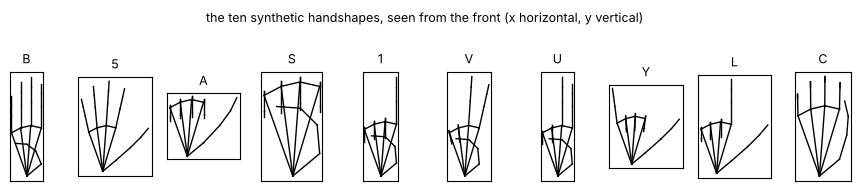

In [2]:
MCP = {"index": (0.30, 1.00), "middle": (0.08, 1.05), "ring": (-0.13, 1.00), "pinky": (-0.32, 0.90)}
LEN = {"index": (0.45, 0.27, 0.20), "middle": (0.50, 0.30, 0.22), "ring": (0.47, 0.28, 0.20), "pinky": (0.37, 0.22, 0.18)}
SPREAD = {"index": 1.0, "middle": 0.3, "ring": -0.4, "pinky": -1.0}
THUMB_CMC, THUMB_LEN = np.array([0.30, 0.25, 0.0]), (0.45, 0.33, 0.27)
PALM = np.array([0.0, 0.0, -1.0])                                                # fingers curl towards -z

def hand(shape, size=1.0):
    # right hand, palm facing the camera: wrist at the origin, fingers along +y, thumb on the +x side
    pts = [np.zeros(3)]
    opp, flex = shape["thumb"]
    d0 = np.cos(opp) * np.array([0.75, 0.66, 0.0]) + np.sin(opp) * np.array([-0.55, 0.35, -0.76])
    d0 /= np.linalg.norm(d0)
    bend = -np.cross(d0, [0, 0, 1.0]); bend /= np.linalg.norm(bend)
    p, th = THUMB_CMC.copy(), 0.0
    pts.append(p.copy())
    for L, a in zip(THUMB_LEN, (0.0, 0.6 * flex, 0.9 * flex)):
        th += a; p = p + L * (np.cos(th) * d0 + np.sin(th) * bend); pts.append(p.copy())
    for k, name in enumerate(["index", "middle", "ring", "pinky"]):
        c = shape["curl"][k]
        a = shape["spread"] * SPREAD[name] * 0.22
        d0 = np.array([np.sin(a), np.cos(a), 0.0])
        p, th = np.array([*MCP[name], 0.0]), 0.0
        pts.append(p.copy())
        for L, ang in zip(LEN[name], (1.45 * c, 1.75 * c, 1.15 * c)):           # bending at the three finger joints
            th += ang; p = p + L * (np.cos(th) * d0 + np.sin(th) * PALM); pts.append(p.copy())
    return np.array(pts) * size

SHAPES = {"B": dict(curl=[0, 0, 0, 0], spread=0.0, thumb=(1.2, 0.6)),   "5": dict(curl=[0, 0, 0, 0], spread=1.0, thumb=(0.0, 0.1)),
          "A": dict(curl=[1, 1, 1, 1], spread=0.0, thumb=(0.15, 0.2)),  "S": dict(curl=[1, 1, 1, 1], spread=0.0, thumb=(1.0, 0.9)),
          "1": dict(curl=[0, 1, 1, 1], spread=0.0, thumb=(1.0, 0.9)),   "V": dict(curl=[0, 0, 1, 1], spread=1.0, thumb=(1.0, 0.9)),
          "U": dict(curl=[0, 0, 1, 1], spread=0.0, thumb=(1.0, 0.9)),   "Y": dict(curl=[1, 1, 1, 0], spread=0.6, thumb=(0.0, 0.1)),
          "L": dict(curl=[0, 1, 1, 1], spread=0.0, thumb=(0.0, 0.1)),   "C": dict(curl=[0.45] * 4, spread=0.1, thumb=(0.7, 0.3))}
NAMES = list(SHAPES)
BONES = [(0, 1), (1, 2), (2, 3), (3, 4), (0, 5), (5, 6), (6, 7), (7, 8), (0, 9), (9, 10), (10, 11), (11, 12), (0, 13), (13, 14),
         (14, 15), (15, 16), (0, 17), (17, 18), (18, 19), (19, 20), (5, 9), (9, 13), (13, 17)]

fig, ax = plt.subplots(1, 10, figsize=(9, 1.9))
for a, name in zip(ax, NAMES):
    P = hand(SHAPES[name])
    for i, j in BONES:
        a.plot(P[[i, j], 0], P[[i, j], 1], "k-", lw=1)
    a.set_aspect("equal"); a.set_title(name, fontsize=9); a.set_xticks([]); a.set_yticks([])
plt.suptitle("the ten synthetic handshapes, seen from the front (x horizontal, y vertical)", fontsize=9)
plt.tight_layout(); plt.show()

### 3. Twenty synthetic signers
Each synthetic signer has a hand size (0.85 to 1.15) and a personal **style**: small fixed offsets in how far they curl each finger, spread their fingers and place the thumb. Every sample adds a little random variation, a random 3-D rotation of the hand (turned up to about 50°, tilted up to about 35°, rolled up to about 60°), a random size in the image (distance to the camera), a random position, and landmark noise like a detector's jitter. Four of the twenty signers are left-handed: their hands are mirror images. Each signer makes each handshape 15 times: 3,000 samples.

In [3]:
rng = np.random.default_rng(0)

def rotation(yaw, pitch, roll):
    cy, sy, cp, sp, cr, sr = np.cos(yaw), np.sin(yaw), np.cos(pitch), np.sin(pitch), np.cos(roll), np.sin(roll)
    return (np.array([[cr, -sr, 0], [sr, cr, 0], [0, 0, 1]]) @ np.array([[1, 0, 0], [0, cp, -sp], [0, sp, cp]])
            @ np.array([[cy, 0, sy], [0, 1, 0], [-sy, 0, cy]]))

def make_signer(left):
    return dict(size=rng.uniform(0.85, 1.15), left=left,
                curl=rng.normal(0, 0.15, 4), spread=rng.normal(0, 0.3), thumb=rng.normal(0, 0.25, 2))

def sample(signer, name, noise=0.08):
    sh = SHAPES[name]
    styled = dict(curl=[float(np.clip(c + o + rng.normal(0, noise), 0, 1.1)) for c, o in zip(sh["curl"], signer["curl"])],
                  spread=sh["spread"] + signer["spread"] + rng.normal(0, noise),
                  thumb=tuple(t + o + rng.normal(0, noise) for t, o in zip(sh["thumb"], signer["thumb"])))
    P = hand(styled, signer["size"]) @ rotation(rng.uniform(-0.9, 0.9), rng.uniform(-0.6, 0.6), rng.uniform(-1.0, 1.0)).T
    P = P * rng.uniform(0.6, 1.6)
    P[:, :2] += rng.uniform(-2, 2, 2)
    P += rng.normal(0, 0.04, P.shape)
    if signer["left"]:
        P[:, 0] = -P[:, 0]                                                       # a left hand is a mirror image of a right hand
    P[:, 2] -= P[0, 2]                                                           # depth relative to the wrist, as MediaPipe reports it
    return P

signers = [make_signer(left=(s % 5 == 4)) for s in range(20)]
X, y, g = [], [], []
for s, sg in enumerate(signers):
    for c, name in enumerate(NAMES):
        for _ in range(15):
            X.append(sample(sg, name)); y.append(c); g.append(s)
X, y, g = np.array(X), np.array(y), np.array(g)
left = np.array([signers[s]["left"] for s in g])
print(f"landmarks: {X.shape} (samples, landmarks, xyz); left-handed signers: {[s for s in range(20) if signers[s]['left']]}")

landmarks: (3000, 21, 3) (samples, landmarks, xyz); left-handed signers: [4, 9, 14, 19]


### 4. Normalization, mirroring and invariant features
* **Normalize:** translate so the wrist is at the origin; divide by the palm size (wrist to landmark 9); rotate into a hand-centred frame where the y axis points from the wrist to landmark 9 and the x axis points from the little-finger knuckle (17) towards the index knuckle (5). This removes position, size and rotation.
* **Mirror:** a rotation cannot turn a left hand into a right hand. If the detector says the hand is a left hand, flip x before normalizing.
* **Distances:** the 210 distances between all pairs of landmarks, divided by the palm size, do not change under rotation, translation or mirroring at all; but they cannot tell a left hand from a right hand (Course 7 session 7 makes the same point about mirror-image molecules).

raw coordinates         : 63 features
normalized              : 63 features
normalized + mirroring  : 63 features
pairwise distances      : 210 features


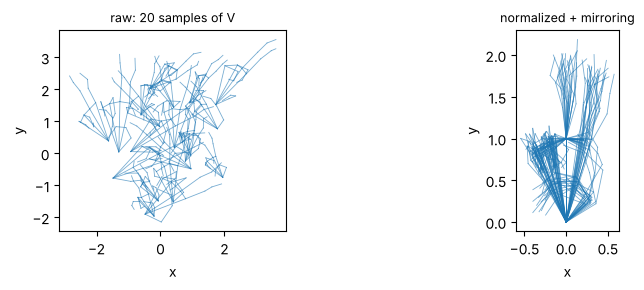

In [4]:
def normalize(P, mirror=None):
    P = P - P[:, :1]                                                             # wrist to the origin
    P = P / np.linalg.norm(P[:, 9], axis=1)[:, None, None]                       # palm size 1
    if mirror is not None:
        P = P.copy(); P[mirror, :, 0] *= -1                                     # left hands -> right hands
    yax = P[:, 9] / np.linalg.norm(P[:, 9], axis=1, keepdims=True)
    xv = P[:, 5] - P[:, 17]
    xax = xv - (xv * yax).sum(1, keepdims=True) * yax
    xax /= np.linalg.norm(xax, axis=1, keepdims=True)
    frame = np.stack([xax, yax, np.cross(xax, yax)], axis=2)                    # columns: the hand's own x, y, z axes
    return np.einsum("nij,njk->nik", P, frame)

iu = np.triu_indices(21, 1)
dist = np.linalg.norm(X[:, :, None] - X[:, None], axis=-1)
FEATURES = {"raw coordinates": X.reshape(len(X), -1),
            "normalized": normalize(X).reshape(len(X), -1),
            "normalized + mirroring": normalize(X, mirror=left).reshape(len(X), -1),
            "pairwise distances": (dist / dist[:, 0, 9][:, None, None])[:, iu[0], iu[1]]}
for k, v in FEATURES.items():
    print(f"{k:24s}: {v.shape[1]} features")

V = y == NAMES.index("V")
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
for a, P, title in [(ax[0], X[V][:20], "raw: 20 samples of V"), (ax[1], normalize(X[V][:20], left[V][:20]), "normalized + mirroring")]:
    for Q in P:
        for i, j in BONES:
            a.plot(Q[[i, j], 0], Q[[i, j], 1], "-", lw=0.6, color="C0", alpha=0.6)
    a.set_aspect("equal"); a.set_title(title, fontsize=9); a.set_xlabel("x"); a.set_ylabel("y")
plt.tight_layout(); plt.show()

### 5. Random split against new signers
A **random split** puts samples of every signer in both the training and the test set, so the model can learn each person's style. A **signer-independent split** tests on people the model has never seen, which is what a real user is. Signers 15–19 form the new-signer test set (one of them, signer 19, is left-handed). We train k-nearest neighbours (k = 5) and a small multilayer perceptron (MLP) on each kind of feature.

features                 split          kNN    MLP   (MLP on the left-handed test signer)


raw coordinates          random       0.417  0.875  (0.802)


raw coordinates          new signers  0.391  0.817  (0.593)


normalized               random       0.933  0.963  (0.966)


normalized               new signers  0.900  0.915  (0.727)


normalized + mirroring   random       0.940  0.973  (0.991)


normalized + mirroring   new signers  0.916  0.944  (0.893)


pairwise distances       random       0.940  0.968  (0.974)


pairwise distances       new signers  0.903  0.925  (0.873)


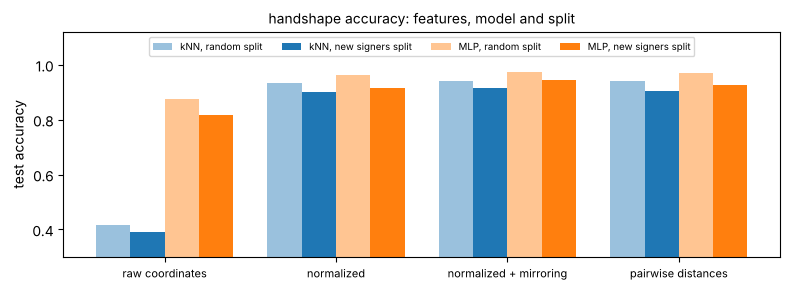

In [5]:
test_new = np.isin(g, [15, 16, 17, 18, 19])
test_random = np.zeros(len(X), bool); test_random[rng.permutation(len(X))[:len(X) // 5]] = True

def models():
    return {"kNN": make_pipeline(StandardScaler(), KNeighborsClassifier(5)),
            "MLP": make_pipeline(StandardScaler(), MLPClassifier((64,), alpha=1e-3, max_iter=200, random_state=0))}

acc, preds = {}, {}
print(f"{'features':24s} {'split':12s}   kNN    MLP   (MLP on the left-handed test signer)")
for fname, F in FEATURES.items():
    for split, te in [("random", test_random), ("new signers", test_new)]:
        row = []
        for mname, m in models().items():
            pred = m.fit(F[~te], y[~te]).predict(F[te])
            acc[fname, split, mname] = (pred == y[te]).mean(); preds[fname, split, mname] = pred
            row.append(acc[fname, split, mname])
        lh = (pred[left[te]] == y[te][left[te]]).mean()
        print(f"{fname:24s} {split:12s} {row[0]:.3f}  {row[1]:.3f}  ({lh:.3f})")

fig, ax = plt.subplots(figsize=(8, 3))
xs = np.arange(len(FEATURES))
for k, (split, mname) in enumerate([("random", "kNN"), ("new signers", "kNN"), ("random", "MLP"), ("new signers", "MLP")]):
    ax.bar(xs + (k - 1.5) * 0.2, [acc[f, split, mname] for f in FEATURES], 0.2, label=f"{mname}, {split} split",
           color=["C0", "C0", "C1", "C1"][k], alpha=[0.45, 1, 0.45, 1][k])
ax.set_xticks(xs); ax.set_xticklabels(list(FEATURES), fontsize=8); ax.set_ylim(0.3, 1.12); ax.set_ylabel("test accuracy")
ax.set_title("handshape accuracy: features, model and split", fontsize=10); ax.legend(fontsize=7, ncol=4, loc="upper center")
plt.tight_layout(); plt.show()

### 6. Which handshapes are confused, and for whom?
The confusion matrix of the best new-signer model shows which handshapes it mixes up; the per-signer accuracy shows that "the" accuracy hides differences between people.

largest confusions (count, true handshape, predicted): [(13, 'V', 'U'), (13, 'U', 'V'), (11, 'S', 'A'), (2, '1', 'V'), (1, 'L', 'A')]
signer 15               : accuracy 0.947
signer 16               : accuracy 0.960
signer 17               : accuracy 0.947
signer 18               : accuracy 0.973
signer 19 (left-handed) : accuracy 0.893


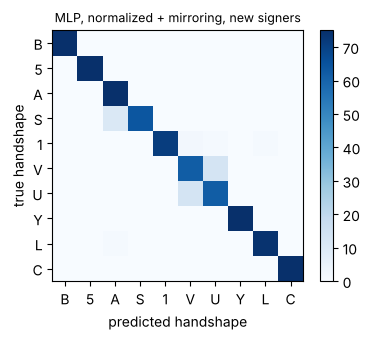

runtime so far 11 s


In [6]:
best = ("normalized + mirroring", "new signers", "MLP")
pred, true = preds[best], y[test_new]
C = confusion_matrix(true, pred, labels=range(10))
off = [(int(C[i, j]), NAMES[i], NAMES[j]) for i in range(10) for j in range(10) if i != j and C[i, j] > 0]
print("largest confusions (count, true handshape, predicted):", sorted(off, reverse=True)[:5])
for s in [15, 16, 17, 18, 19]:
    m = g[test_new] == s
    print(f"signer {s}{' (left-handed)' if signers[s]['left'] else '':15s}: accuracy {(pred[m] == true[m]).mean():.3f}")

plt.figure(figsize=(4.2, 3.5))
plt.imshow(C, cmap="Blues"); plt.colorbar(fraction=0.046)
plt.xticks(range(10), NAMES); plt.yticks(range(10), NAMES)
plt.xlabel("predicted handshape"); plt.ylabel("true handshape"); plt.title("MLP, normalized + mirroring, new signers", fontsize=9)
plt.tight_layout(); plt.show()
print(f"runtime so far {time.time() - t_start:.0f} s")

### 7. From photos to landmarks (NOT RUN here)
The current MediaPipe release (1.2.3, checked in November 2026) provides hand landmarks through its Tasks API: a `HandLandmarker` with a model file, `hand_landmarker.task`, downloaded from the MediaPipe documentation. Several Bangla Sign Language (BdSL) alphabet and word datasets have been published by research groups in Bangladesh: use one whose licence allows your use, read how it was collected, and record how many signers it has before you trust any accuracy reported on it. The cell assumes one folder of photos per sign class.

In [ ]:
# NOT RUN: needs mediapipe (pip install mediapipe), the hand_landmarker.task model file and a folder of hand photos
import mediapipe as mp
from mediapipe.tasks.python import BaseOptions, vision
from pathlib import Path
detector = vision.HandLandmarker.create_from_options(
    vision.HandLandmarkerOptions(base_options=BaseOptions(model_asset_path="hand_landmarker.task"), num_hands=1))
rows, missed = [], 0
for path in sorted(Path("bdsl_alphabet").glob("*/*.jpg")):                       # bdsl_alphabet/<class name>/<photo>.jpg
    image = mp.Image.create_from_file(str(path))
    result = detector.detect(image)
    if not result.hand_landmarks:
        missed += 1; continue                                                   # report how many photos had no hand found
    h, w = image.numpy_view().shape[:2]
    pts = np.array([[p.x * w, p.y * h, p.z * w] for p in result.hand_landmarks[0]])   # x, y are fractions of width, height
    rows.append((path.parent.name, result.handedness[0][0].category_name == "Left", pts))
print(f"{len(rows)} photos with a hand, {missed} without")

### 8. Exercises

In [7]:
# TODO: angle features. Write joint_angles(P) that returns, for every finger and the thumb, the bending angle at each
# joint (the angle between consecutive bones, as in question 4 of section 1): 15 angles per hand. Train the MLP on the
# angles alone with the new-signer split. Angles do not change with rotation, size or mirroring. Do they beat distances?
def joint_angles(P):
    return None          # replace with your code: an array of shape (len(P), 15)

r = joint_angles(X[:5])
print("not done yet" if r is None else r.shape)

not done yet


In [8]:
# TODO: leave-one-signer-out. Instead of one fixed test set of five signers, train 20 times, each time leaving one
# signer out, with the "normalized + mirroring" features and kNN. Report the mean accuracy, the worst signer and the
# best signer. How much does one number (the mean) hide?
def leave_one_signer_out():
    return None          # replace with your code: return a list of 20 accuracies

r = leave_one_signer_out()
print("not done yet" if r is None else f"mean {np.mean(r):.3f}, worst {np.min(r):.3f}, best {np.max(r):.3f}")

not done yet


### What to notice
(Written from the run above; your numbers will match if you keep the seeds.)

1. **The hand calculations.** The palm size is 2.0, so landmark 9 becomes (0, 1). The turned hand needs a rotation of 90° clockwise to point up again, and the finger joint bends by 36.9°.
2. **Raw coordinates mislead nearest neighbours.** On raw landmarks, k-nearest neighbours scored 0.417 (random split) and 0.391 (new signers): the closest stored hands were the ones in a similar place and pose, not the same shape. The MLP learned part of the invariance from 2,250 to 2,400 training samples, 0.875 and 0.817, which was better than we expected, but still well below normalized features.
3. **Normalization does most of the work.** With normalized landmarks kNN reached 0.933 and 0.900, and the MLP 0.963 and 0.915.
4. **New signers are harder in every row.** With the best features (normalized + mirroring), kNN fell from 0.940 on the random split to 0.916 on new signers, and the MLP from 0.973 to 0.944. A random split lets the model learn each person's style, so it overstates what a new user will get.
5. **Mirroring matters, and the random split hid it.** On the left-handed new signer, the MLP scored 0.727 without mirroring and 0.893 with it. On the random split the left-handed samples already scored 0.966 without mirroring, because the same left-handed people were in the training set.
6. **Distances are a strong, simple choice.** The 210 pairwise distances need no rotation and no handedness, and gave 0.925 on new signers with the MLP, close to the 0.944 of normalized + mirroring. They cannot tell a left hand from a right hand.
7. **Errors follow the small differences.** The largest confusions were V and U (13 each way) and S taken for A (11): the pairs that differ only in finger spread or thumb position. Per signer, accuracy ranged from 0.947 to 0.973 for the four right-handed new signers but was 0.893 for the left-handed one: report results per signer, not only on average.